In [97]:
import csv
import PyPDF2
import numpy as np
import nltk
from nltk import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.decomposition import PCA
import glob, os
import pandas as pd
from gensim.models import KeyedVectors
from gensim.models import Word2Vec
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from numpy import dot
from numpy.linalg import norm

In [ ]:
sentences = [
    ["solar", "power", "lights", "up", "homes", "with", "sunlight"],
    ["wind", "turbines", "spin", "for", "clean", "energy"],
    ["electric", "cars", "cut", "emissions"],
    ["biomass", "fuels", "sustainable", "heat"],
    ["green", "homes", "save", "energy"]
]

model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, sg=0)
target_words = ["solar", "wind", "energy", "electric", "sustainable", "emissions"]
word_vectors = np.array([model.wv[word] for word in target_words])

pca = PCA(n_components=2)
word_vectors_2d = pca.fit_transform(word_vectors)

plt.figure(figsize=(12, 8))
plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1], marker='o', color='b')

x_annotation_offset = 0.0004
y_annotation_offset = 0.0006
for i, word in enumerate(target_words):
    plt.annotate(word, xy=(word_vectors_2d[i, 0] + x_annotation_offset, word_vectors_2d[i, 1] - y_annotation_offset), fontsize=12, ha='center', va='top')

plt.xlabel('Principal Component 1', fontsize = 14)
plt.ylabel('Principal Component 2', fontsize = 14)
plt.title('Word Similarity Visualisation', fontsize = 18)
plt.grid(color='lightgrey', linestyle='--', linewidth=0.5)

plt.savefig('word_similarity_plot.png', dpi=300)
plt.show()

In [2]:
inputs = 'C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A'
outputs = 'C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions'
bigrams = 'C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/bigram'
vectors= 'C:/Users/aznur/Desktop/Projects/nlp_analysis/GoogleNews-vectors-negative300.bin'

In [3]:
os.chdir(input)
all_pdfs = []
for file in glob.glob("*pdf"):
    all_pdfs.append(file)

In [6]:
pdf_names = [os.path.splitext(i)[0] for i in all_pdfs]

In [8]:
info = [['Document', 'Page_Count', 'Count_Total_Words', 'Top_Count', 'Ratio']]

In [9]:
def top_words(top_count, all_pdfs, pdf_names, info_being_gathered):
    
    list_of_100_words = []

    for pdf, pdf_name in zip(all_pdfs, pdf_names):
        
        count_word = top_count

        pdfFileObj = open(pdf, 'rb')

        pdfReader = PyPDF2.PdfReader(pdfFileObj)

        num_pages = len(pdfReader.pages)
        count = 0
        text = ""

        while count < num_pages:
            pageObj = pdfReader.pages[count]
            count += 1
            text += pageObj.extract_text()
            
        page_count = count

        tokens = word_tokenize(text)

        tokens = [word for word in tokens if len(word) > 1]
        punctuations = ['(', ')', ';', ':', '[', ']', ',', '.']

        stop_words = stopwords.words('english')
        also_stop_words = ['also', 'total', 'use', 'new']
        
        total_stop_words = stop_words + also_stop_words

        keywords = [word for word in tokens if not word.lower() in total_stop_words and not word in punctuations]
        keywords = [i for i in keywords if i.isalpha()]

        f_dist = FreqDist()
        for word in keywords:
            f_dist[word.lower()] += 1
        
        bgs = nltk.bigrams(keywords)

        fdist2 = nltk.FreqDist(bgs)
        
        list_of_100_words.append(f_dist.most_common(count_word))
        pdf_final_name = pdf_name + ".csv"
        final_path = os.path.join(output, pdf_final_name)
        final_path_bigrm = os.path.join(bigrams, pdf_final_name)
        
        total_sum = sum(f_dist.values())
        top_count_sum= sum(j for i, j in f_dist.most_common(count_word))
        percentage = (top_count_sum/total_sum)*100
        name = pdf_name
        
        info_per_pdf = [name, page_count, total_sum, top_count_sum, percentage]
        info_being_gathered.append(info_per_pdf)
        
        with open(final_path, 'w', encoding='utf-8', newline='') as file:
            writer = csv.writer(file)
            writer.writerow(["word", "weight"])
            writer.writerows(f_dist.most_common(count_word))
            
        with open(final_path_bigrm, 'w', encoding='utf-8', newline='') as file:
            writer = csv.writer(file)
            writer.writerow(["word", "weight"])
            writer.writerows(fdist2.most_common(count_word))
        
        print(list_of_100_words)  
        print("-----------NEXT---------")
        print("For document ", pdf_name)
        print(f_dist.most_common(count_word))
        
    return info, list_of_100_words

In [10]:
information_100, list_of_100_words = top_words(100, all_pdfs, pdf_names, info)

The no of pages in the document is  6
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

The no of pages in the document is  8
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

The no of pages in the document is  7
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

The no of pages in the document is  9
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

The no of pages in the document is  11
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6

The no of pages in the document is  8
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

... (104 outputs left out)

The no of pages in the document is  10
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6

The no of pages in the document is  12
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6

The no of pages in the document is  12
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6

The no of pages in the document is  8
[[('catalyst', 45), ('reaction', 35), ('mol', 26), ('pressure', 24), ('time', 17), ('selectivity', 16), ('catal', 16), ('hydrogen', 15), ('peroxide', 15), ('yield', 15), ('effect', 14), ('using', 14), ('fig', 14), ('pd', 13), ('direct', 12), ('process', 12), ('conditions', 12), ('gases', 12), ('obtained', 12), ('high', 11), ('synthesis', 9), ('pressures', 9), ('transfer', 9), ('gas', 9), ('used', 9), ('mass', 9), ('solubility', 9), ('mpa', 9), ('ratio', 9), ('general', 8), ('increasing', 8), ('reactions', 8), ('although', 8), ('al', 8), ('promoters', 8), ('hutchings', 8), ('table', 8), ('run', 8), ('appl', 8), ('chem', 8), ('applied', 7), ('catalysis', 7), ('methanol', 7), ('catalysts', 7), ('work', 7), ('et', 7), ('see', 7), ('moreno', 7), ('results', 7), ('surface', 7), ('ﬂow', 7), ('carley', 7), ('solvent', 6), ('concentration', 6), ('reactor', 6), ('tion', 6), ('rate', 6), ('role', 6), ('highest', 6), ('fresh', 6), ('runs', 6), ('choudhary', 6)

In [12]:
all_top_words = []
for i in list_of_100_words:
    for j in i:
        all_top_words.append(j)

In [13]:
all_top_words

[('catalyst', 45),
 ('reaction', 35),
 ('mol', 26),
 ('pressure', 24),
 ('time', 17),
 ('selectivity', 16),
 ('catal', 16),
 ('hydrogen', 15),
 ('peroxide', 15),
 ('yield', 15),
 ('effect', 14),
 ('using', 14),
 ('fig', 14),
 ('pd', 13),
 ('direct', 12),
 ('process', 12),
 ('conditions', 12),
 ('gases', 12),
 ('obtained', 12),
 ('high', 11),
 ('synthesis', 9),
 ('pressures', 9),
 ('transfer', 9),
 ('gas', 9),
 ('used', 9),
 ('mass', 9),
 ('solubility', 9),
 ('mpa', 9),
 ('ratio', 9),
 ('general', 8),
 ('increasing', 8),
 ('reactions', 8),
 ('although', 8),
 ('al', 8),
 ('promoters', 8),
 ('hutchings', 8),
 ('table', 8),
 ('run', 8),
 ('appl', 8),
 ('chem', 8),
 ('applied', 7),
 ('catalysis', 7),
 ('methanol', 7),
 ('catalysts', 7),
 ('work', 7),
 ('et', 7),
 ('see', 7),
 ('moreno', 7),
 ('results', 7),
 ('surface', 7),
 ('ﬂow', 7),
 ('carley', 7),
 ('solvent', 6),
 ('concentration', 6),
 ('reactor', 6),
 ('tion', 6),
 ('rate', 6),
 ('role', 6),
 ('highest', 6),
 ('fresh', 6),
 ('runs',

In [14]:
df_all_words = pd.DataFrame(all_top_words, columns=['Word', 'Count'])

In [15]:
words_occurance_in_documents = df_all_words.groupby('Word').agg({'Count':'count'}).sort_values(by='Count', ascending=False)

In [17]:
words_occurance_in_documents

,Count
Word,
catalysis,128
applied,127
al,118
general,106
catalyst,104
...,...
hydration,1
hydride,1
hydrocarbonaceous,1


In [18]:
word_occuring_in_all_documents = words_occurance_in_documents[words_occurance_in_documents['Count']>=70].reset_index()

In [19]:
word_occuring_in_all_documents

,Word,Count
0,catalysis,128
1,applied,127
2,al,118
3,general,106
4,catalyst,104
5,reaction,104
6,catalysts,93
7,using,88
8,et,87
9,fig,83


In [20]:
os.chdir(outputs)
word_occuring_in_all_documents.to_csv('most_common_new.csv', index=False)

In [21]:
information_100

[['Document', 'Page_Count', 'Count_Total_Words', 'Top_Count', 'Ratio'],
 ['1-s2.0-S0926860X10005041-main', 6, 1884, 840, 44.5859872611465],
 ['1-s2.0-S0926860X1000520X-main', 7, 2258, 1045, 46.279893711248896],
 ['1-s2.0-S0926860X1000606X-main', 6, 2207, 1219, 55.23334843679203],
 ['1-s2.0-S0926860X10006939-main', 8, 3087, 1377, 44.606413994169095],
 ['1-s2.0-S0926860X10007246-main', 6, 2033, 1004, 49.38514510575504],
 ['1-s2.0-S0926860X10007611-main', 7, 2462, 1204, 48.90333062550772],
 ['1-s2.0-S0926860X11000032-main', 9, 3539, 1865, 52.698502401808426],
 ['1-s2.0-S0926860X11001207-main', 11, 4629, 1902, 41.08878807517822],
 ['1-s2.0-S0926860X1100247X-main', 8, 2642, 1217, 46.06358819076457],
 ['1-s2.0-S0926860X1100250X-main', 9, 2876, 1247, 43.35883171070932],
 ['1-s2.0-S0926860X11005308-main', 9, 3875, 1872, 48.30967741935484],
 ['1-s2.0-S0926860X11005692-main', 5, 1812, 856, 47.24061810154526],
 ['1-s2.0-S0926860X1100754X-main', 9, 3268, 1576, 48.225214198286416],
 ['1-s2.0-S09268

In [22]:
df = pd.DataFrame(information_100, columns=information_100.pop(0))
df.to_csv('Information_100_word_count.csv', index=False)

In [23]:
df

,Document,Page_Count,Count_Total_Words,Top_Count,Ratio
0,1-s2.0-S0926860X10005041-main,6,1884,840,44.585987
1,1-s2.0-S0926860X1000520X-main,7,2258,1045,46.279894
2,1-s2.0-S0926860X1000606X-main,6,2207,1219,55.233348
3,1-s2.0-S0926860X10006939-main,8,3087,1377,44.606414
4,1-s2.0-S0926860X10007246-main,6,2033,1004,49.385145
...,...,...,...,...,...
123,10.1016%j.apcata.2022.118817,7,3092,1270,41.073739
124,10.1016%j.apcata.2022.118899,10,4004,1917,47.877123
125,10.1016%j.apcata.2022.118924,12,5626,2389,42.463562
126,10.1016%j.apcata.2023.119039,12,5256,1798,34.208524


The process above was repeated for each journal to obtain most_common_new.csv file.

In [3]:
model = KeyedVectors.load_word2vec_format(vectors, binary=True)

In [123]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/most_common_new.csv')

In [124]:
energy = [word for word in energy['Word'] if len(word) > 3]

In [125]:
energy = energy[:12]

In [126]:
energy

['control',
 'international',
 'journal',
 'greenhouse',
 'carbon',
 'storage',
 'using',
 'used',
 'capture',
 'energy',
 'pressure',
 'data']

In [127]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

In [128]:
words = energy+male_words+female_words

In [129]:
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = model[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

In [130]:
new=pd.DataFrame(all_values)
new.index=valid_words

In [131]:
new

,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
control,0.149414,0.067383,-0.092773,-0.205078,-0.175781,-0.024048,0.094727,-0.130859,0.022461,-0.103516,...,-0.312500,0.194336,0.037109,0.044922,-0.053711,-0.022949,-0.253906,0.019775,-0.171875,-0.112793
international,-0.251953,0.171875,0.099609,0.069824,0.104980,-0.159180,-0.022339,-0.316406,-0.040283,-0.007751,...,0.021362,0.075684,0.020142,0.083496,0.063965,0.073242,0.065430,0.229492,0.066406,-0.101074
journal,-0.026489,-0.073730,-0.069336,0.125977,0.217773,0.190430,0.013550,-0.164062,0.225586,-0.171875,...,-0.001305,-0.277344,-0.200195,0.320312,-0.038574,-0.058594,-0.151367,0.078125,0.189453,0.241211
greenhouse,-0.091797,0.078125,0.085449,-0.066406,0.065918,-0.074219,0.376953,-0.028442,-0.071289,0.110352,...,-0.384766,0.312500,0.010010,0.060059,-0.029541,0.118652,-0.060059,0.228516,0.404297,0.041504
carbon,0.223633,0.054932,-0.028809,-0.012451,-0.155273,-0.199219,0.140625,-0.111328,0.155273,0.369141,...,-0.302734,-0.019287,0.294922,-0.080566,-0.167969,0.109375,0.244141,0.133789,0.202148,0.079102
storage,-0.108398,0.273438,-0.006317,-0.185547,0.063965,0.174805,0.061279,-0.197266,0.371094,0.175781,...,-0.172852,0.032227,0.047607,0.244141,0.130859,-0.216797,0.074219,0.045898,-0.103516,0.006195
using,0.134766,-0.001419,0.085449,0.058350,-0.060059,0.175781,-0.051025,-0.080078,-0.080566,0.187500,...,-0.125000,0.091309,-0.061768,0.063477,-0.013611,-0.055420,0.224609,-0.056641,-0.267578,0.108398
used,0.202148,0.113770,0.241211,0.107910,-0.224609,-0.021606,0.107422,-0.072266,0.086914,0.077637,...,-0.110352,-0.008118,-0.066406,-0.009094,-0.123535,-0.094238,0.168945,-0.075195,-0.163086,0.029053
capture,0.033691,0.279297,-0.134766,-0.246094,-0.122070,-0.041504,-0.072754,0.022949,0.133789,0.164062,...,-0.144531,0.146484,0.034912,0.006226,-0.201172,-0.104492,0.227539,-0.285156,0.166992,-0.109375
energy,-0.103516,0.161133,0.117188,-0.253906,0.008911,0.008240,0.103027,-0.400391,0.094238,0.030640,...,-0.237305,-0.132812,-0.015198,-0.093262,-0.079102,-0.065430,0.186523,0.045898,0.153320,0.240234


In [132]:
pca = PCA(n_components=2)
result = pca.fit_transform(new)

In [133]:
result

array([[ 0.5541738 , -1.0556569 ],
       [ 0.22661762, -0.34352222],
       [ 0.27013323, -0.48390296],
       [ 1.1644127 ,  1.3417698 ],
       [ 2.1289394 ,  2.0962272 ],
       [ 1.1750658 , -0.746463  ],
       [ 0.35250595, -0.6543445 ],
       [ 0.3179302 , -0.6175243 ],
       [ 0.39839384, -0.78325814],
       [ 1.2109325 ,  0.50240135],
       [ 0.74473846, -0.65752834],
       [ 0.84344923, -1.2875028 ],
       [-1.2168982 , -0.11484829],
       [-0.9480547 ,  0.3647623 ],
       [-0.3824964 ,  0.13505752],
       [-0.61662585,  0.16281548],
       [-0.54768604,  0.21763569],
       [-1.2845922 ,  0.00369706],
       [-1.5600995 ,  0.5823477 ],
       [-0.9146049 ,  0.39348546],
       [-1.0803039 ,  0.44285825],
       [-0.8359308 ,  0.50149333]], dtype=float32)

In [134]:
def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (norm(v1) * norm(v2))

pronouns = list(word_colours.keys())

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in word_colours]

cosine_similarities = {}

for pronoun in pronouns:
    idx_pronoun = new.index.get_loc(pronoun)
    vec_pronoun = result[idx_pronoun]

    for idx_word in non_pronoun_indices:
        word = new.index[idx_word]
        vec_word = result[idx_word]

        similarity = cosine_similarity(vec_pronoun, vec_word)

        cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

('he', 'control'): -0.73
('he', 'international'): -0.80
('he', 'journal'): -0.75
('he', 'greenhouse'): -0.37
('he', 'carbon'): -0.44
('he', 'storage'): -0.97
('he', 'using'): -0.74
('he', 'used'): -0.73
('he', 'capture'): -0.72
('he', 'energy'): -0.74
('he', 'pressure'): -0.93
('he', 'data'): -0.80
('male', 'control'): -0.38
('male', 'international'): -0.47
('male', 'journal'): -0.40
('male', 'greenhouse'): -0.72
('male', 'carbon'): -0.78
('male', 'storage'): -0.79
('male', 'using'): -0.39
('male', 'used'): -0.37
('male', 'capture'): -0.37
('male', 'energy'): -0.96
('male', 'pressure'): -0.68
('male', 'data'): -0.47
('man', 'control'): -0.75
('man', 'international'): -0.81
('man', 'journal'): -0.77
('man', 'greenhouse'): -0.34
('man', 'carbon'): -0.41
('man', 'storage'): -0.98
('man', 'using'): -0.76
('man', 'used'): -0.75
('man', 'capture'): -0.74
('man', 'energy'): -0.72
('man', 'pressure'): -0.94
('man', 'data'): -0.81
('him', 'control'): -0.68
('him', 'international'): -0.75
('him'

In [135]:
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

In [136]:
df_cosine_similarities 

,Pronoun,Word,Cosine Similarity
0,he,control,-0.733082
1,he,international,-0.797165
2,he,journal,-0.750340
3,he,greenhouse,-0.366569
4,he,carbon,-0.438304
...,...,...,...
115,hers,used,-0.849911
116,hers,capture,-0.847308
117,hers,energy,-0.594915
118,hers,pressure,-0.983316


In [137]:
avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

Overall average cosine distance to male pronouns: 1.6929
Overall average cosine distance to female pronouns: 1.7151


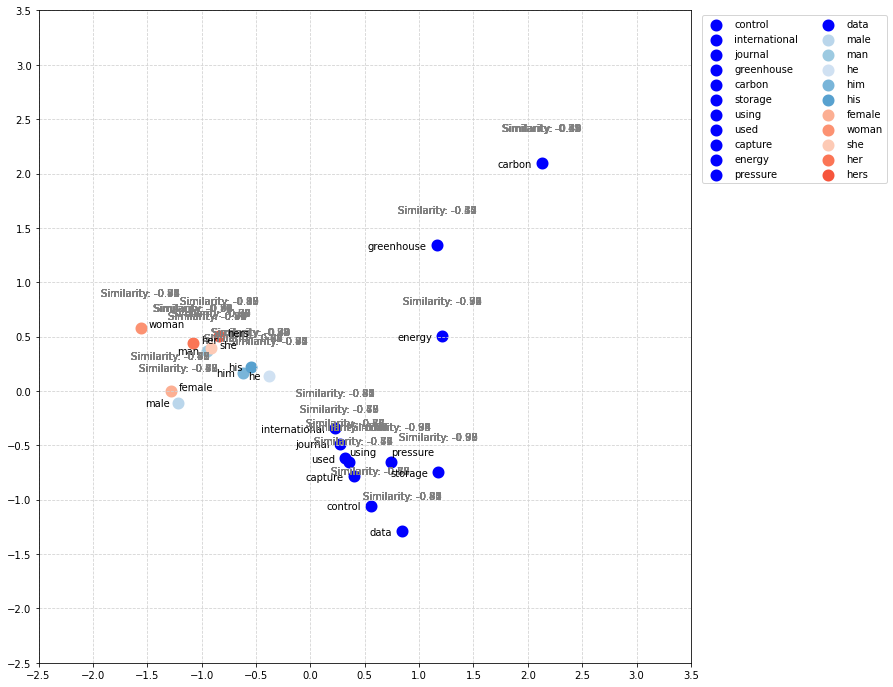

In [138]:
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)
    
    target = ['using', 'pressure']

    if word not in word_colours and word not in target:
        offset = (-10, -4)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in target:
        offset = (0, 7)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (-8, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in female_words:
        offset = (8, 0)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
        
    for (pronoun1, pronoun2), similarity in cosine_similarities.items():
        if word == pronoun1 or word == pronoun2:
            plt.annotate(f"Similarity: {similarity:.2f}", (result[i, 0], result[i, 1] + 0.2), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, color='gray')

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-0.5, x_max + 0.6, 0.5))
plt.yticks(np.arange(y_min-0.5, y_max + 0.6, 0.5))
plt.xlim(x_min-0.5, x_max+0.5)
plt.ylim(y_min-0.5, y_max+0.5)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/word2vec_pretrained_ggs.png', bbox_inches='tight')
plt.show()

('he', 'journal'): -0.79
('he', 'hydrogen'): -0.24
('he', 'energy'): -0.25
('he', 'article'): -0.88
('he', 'online'): -0.86
('he', 'university'): -0.02
('he', 'fuel'): -0.28
('he', 'using'): -1.00
('he', 'received'): -0.43
('he', 'history'): -0.69
('he', 'info'): -0.98
('he', 'revised'): -0.98
('male', 'journal'): -0.42
('male', 'hydrogen'): -0.67
('male', 'energy'): -0.67
('male', 'article'): -0.56
('male', 'online'): -0.53
('male', 'university'): 0.45
('male', 'fuel'): -0.69
('male', 'using'): -0.91
('male', 'received'): 0.04
('male', 'history'): -0.27
('male', 'info'): -0.78
('male', 'revised'): -0.79
('man', 'journal'): -0.67
('man', 'hydrogen'): -0.42
('man', 'energy'): -0.42
('man', 'article'): -0.78
('man', 'online'): -0.76
('man', 'university'): 0.17
('man', 'fuel'): -0.45
('man', 'using'): -0.99
('man', 'received'): -0.26
('man', 'history'): -0.54
('man', 'info'): -0.93
('man', 'revised'): -0.93
('him', 'journal'): -0.60
('him', 'hydrogen'): -0.50
('him', 'energy'): -0.50
('hi

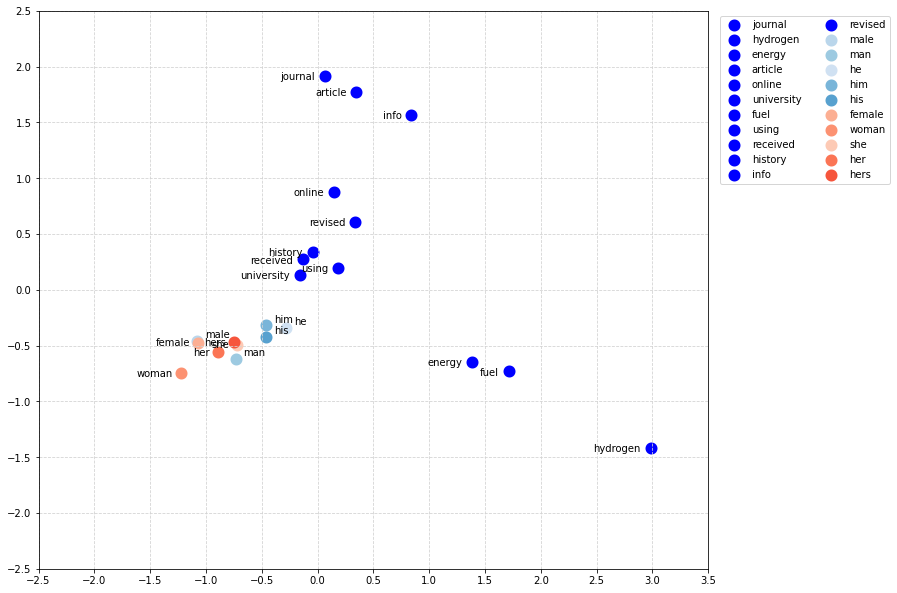

In [139]:
journal_name = 'International Journal of Hydrogen Energy'

energy = pd.read_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/most_common_new.csv')

energy = [word for word in energy['Word'] if len(word) > 3]

energy = energy[:12]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = model[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

new=pd.DataFrame(all_values)
new.index=valid_words

pca = PCA(n_components=2)
result = pca.fit_transform(new)

pronouns = list(word_colours.keys())

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in word_colours]

cosine_similarities = {}

for pronoun in pronouns:
    idx_pronoun = new.index.get_loc(pronoun)
    vec_pronoun = result[idx_pronoun]

    for idx_word in non_pronoun_indices:
        word = new.index[idx_word]
        vec_word = result[idx_word]

        similarity = cosine_similarity(vec_pronoun, vec_word)

        cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/cosine_similarities.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)
    
    target = []

    if word not in word_colours and word not in target:
        offset = (-10, -4)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in target:
        offset = (0, 7)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (8, 3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in female_words:
        offset = (-8, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-0.5, x_max + 0.6, 0.5))
plt.yticks(np.arange(y_min-0.5, y_max + 0.6, 0.5))
plt.xlim(x_min-0.5, x_max+0.5)
plt.ylim(y_min-0.5, y_max+0.5)
plt.savefig(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/word2vec_pretrained_he.png', bbox_inches='tight')
plt.show()

('he', 'catalysis'): -0.85
('he', 'applied'): -0.88
('he', 'general'): -0.16
('he', 'catalyst'): -0.80
('he', 'reaction'): -0.99
('he', 'catalysts'): -0.82
('he', 'using'): -0.11
('he', 'high'): -0.26
('he', 'used'): -0.49
('he', 'temperature'): -0.30
('he', 'surface'): -0.63
('he', 'activity'): -0.40
('male', 'catalysis'): -0.79
('male', 'applied'): -0.93
('male', 'general'): -0.26
('male', 'catalyst'): -0.74
('male', 'reaction'): -1.00
('male', 'catalysts'): -0.76
('male', 'using'): -0.22
('male', 'high'): -0.37
('male', 'used'): -0.58
('male', 'temperature'): -0.40
('male', 'surface'): -0.71
('male', 'activity'): -0.50
('man', 'catalysis'): -0.73
('man', 'applied'): -0.96
('man', 'general'): -0.36
('man', 'catalyst'): -0.67
('man', 'reaction'): -1.00
('man', 'catalysts'): -0.69
('man', 'using'): -0.31
('man', 'high'): -0.46
('man', 'used'): -0.66
('man', 'temperature'): -0.49
('man', 'surface'): -0.77
('man', 'activity'): -0.58
('him', 'catalysis'): -0.68
('him', 'applied'): -0.98
(

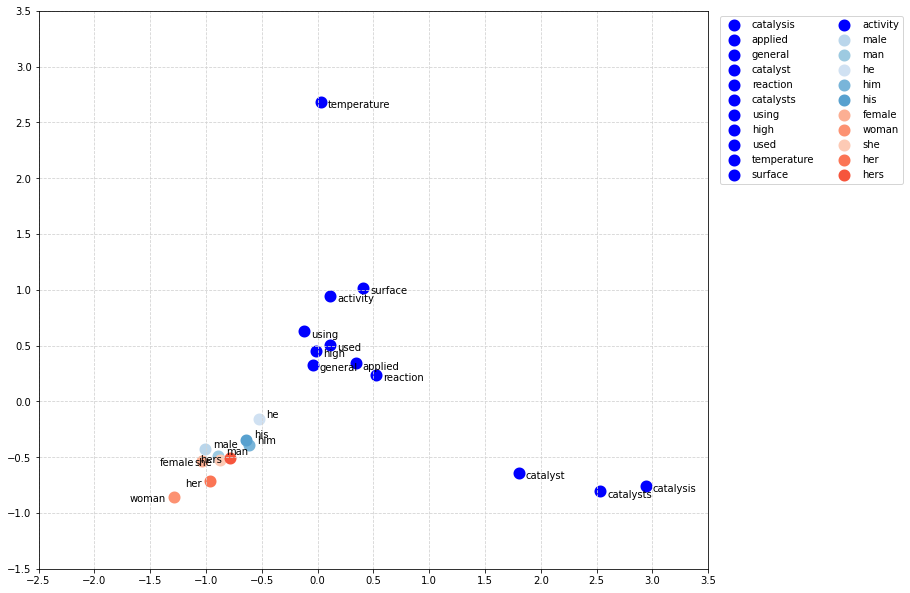

In [140]:
journal_name = 'Applied Catalysis A'

energy = pd.read_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/most_common_new.csv')

energy = [word for word in energy['Word'] if len(word) > 3]

energy = energy[:12]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = model[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

new=pd.DataFrame(all_values)
new.index=valid_words

pca = PCA(n_components=2)
result = pca.fit_transform(new)

pronouns = list(word_colours.keys())

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in word_colours]

cosine_similarities = {}

for pronoun in pronouns:
    idx_pronoun = new.index.get_loc(pronoun)
    vec_pronoun = result[idx_pronoun]

    for idx_word in non_pronoun_indices:
        word = new.index[idx_word]
        vec_word = result[idx_word]

        similarity = cosine_similarity(vec_pronoun, vec_word)

        cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/cosine_similarities.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)
    
    target = []

    if word not in word_colours and word not in target:
        offset = (7, -6)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in target:
        offset = (0, 7)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (8, 2)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in female_words:
        offset = (-8, -5)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-0.5, x_max + 0.6, 0.5))
plt.yticks(np.arange(y_min-0.5, y_max + 0.6, 0.5))
plt.xlim(x_min-0.5, x_max+0.5)
plt.ylim(y_min-0.5, y_max+0.5)
plt.savefig(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/word2vec_pretrained_applied.png', bbox_inches='tight')
plt.show()

('he', 'solar'): -0.31
('he', 'energy'): -0.32
('he', 'using'): 0.57
('he', 'used'): 0.60
('he', 'temperature'): -0.93
('he', 'performance'): 0.11
('he', 'results'): 0.57
('he', 'thermal'): -0.94
('he', 'high'): 0.18
('he', 'system'): -0.06
('he', 'surface'): -0.98
('he', 'heat'): -1.00
('male', 'solar'): -1.00
('male', 'energy'): -1.00
('male', 'using'): -0.58
('male', 'used'): -0.55
('male', 'temperature'): 0.03
('male', 'performance'): -0.90
('male', 'results'): -0.58
('male', 'thermal'): -0.64
('male', 'high'): -0.86
('male', 'system'): -0.96
('male', 'surface'): -0.17
('male', 'heat'): -0.30
('man', 'solar'): -0.90
('man', 'energy'): -0.91
('man', 'using'): -0.20
('man', 'used'): -0.15
('man', 'temperature'): -0.39
('man', 'performance'): -0.64
('man', 'results'): -0.20
('man', 'thermal'): -0.90
('man', 'high'): -0.58
('man', 'system'): -0.76
('man', 'surface'): -0.56
('man', 'heat'): -0.66
('him', 'solar'): -0.49
('him', 'energy'): -0.50
('him', 'using'): 0.40
('him', 'used'): 0.

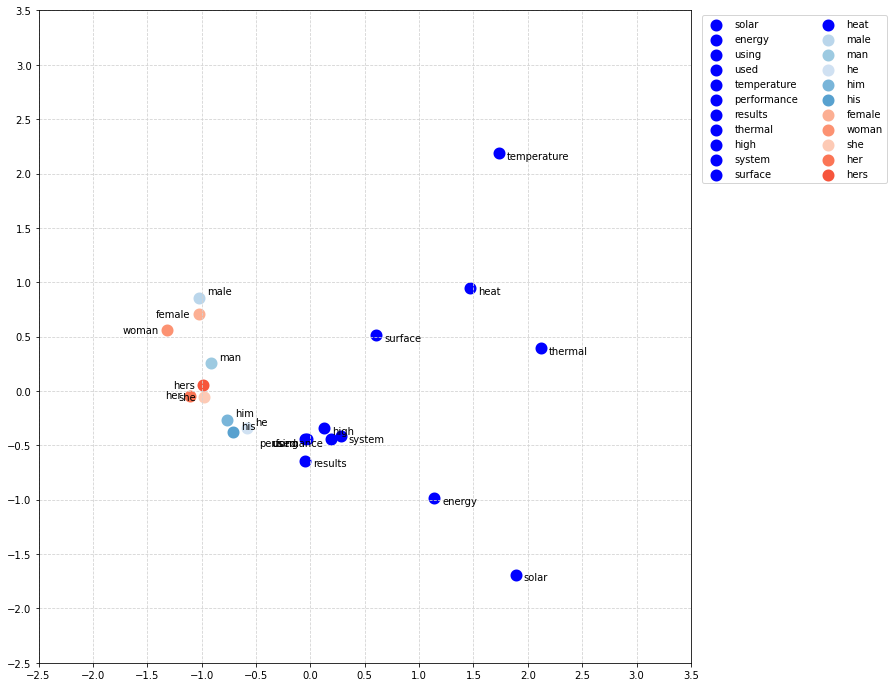

In [141]:
journal_name = 'Solar Energy'

energy = pd.read_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/most_common_new.csv')

energy = [word for word in energy['Word'] if len(word) > 3]

energy = energy[:12]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = model[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

new=pd.DataFrame(all_values)
new.index=valid_words

pca = PCA(n_components=2)
result = pca.fit_transform(new)

pronouns = list(word_colours.keys())

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in word_colours]

cosine_similarities = {}

for pronoun in pronouns:
    idx_pronoun = new.index.get_loc(pronoun)
    vec_pronoun = result[idx_pronoun]

    for idx_word in non_pronoun_indices:
        word = new.index[idx_word]
        vec_word = result[idx_word]

        similarity = cosine_similarity(vec_pronoun, vec_word)

        cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/cosine_similarities.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)
    
    target = ['using', 'used', 'performance']

    if word not in word_colours and word not in target:
        offset = (8, -6)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in target:
        offset = (-8, -7)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in male_words:
        offset = (8, 3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in female_words:
        offset = (-8, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-0.5, x_max + 0.6, 0.5))
plt.yticks(np.arange(y_min-0.5, y_max + 0.6, 0.5))
plt.xlim(x_min-0.5, x_max+0.5)
plt.ylim(y_min-0.5, y_max+0.5)
plt.savefig(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/word2vec_pretrained_se.png', bbox_inches='tight')
plt.show()

('he', 'porous'): -0.68
('he', 'media'): 0.66
('he', 'using'): 0.37
('he', 'used'): 0.38
('he', 'model'): 0.90
('he', 'results'): -0.09
('he', 'different'): 0.62
('he', 'pressure'): 0.26
('he', 'time'): 0.87
('he', 'water'): -0.60
('he', 'permeability'): -0.98
('he', 'shown'): 0.08
('male', 'porous'): -0.67
('male', 'media'): -0.80
('male', 'using'): -0.95
('male', 'used'): -0.95
('male', 'model'): 0.36
('male', 'results'): -0.99
('male', 'different'): -0.83
('male', 'pressure'): -0.98
('male', 'time'): -0.56
('male', 'water'): -0.75
('male', 'permeability'): -0.13
('male', 'shown'): -1.00
('man', 'porous'): -0.84
('man', 'media'): -0.63
('man', 'using'): -0.85
('man', 'used'): -0.84
('man', 'model'): 0.59
('man', 'results'): -1.00
('man', 'different'): -0.66
('man', 'pressure'): -0.91
('man', 'time'): -0.34
('man', 'water'): -0.89
('man', 'permeability'): -0.37
('man', 'shown'): -0.97
('him', 'porous'): -0.89
('him', 'media'): 0.35
('him', 'using'): 0.03
('him', 'used'): 0.04
('him', 

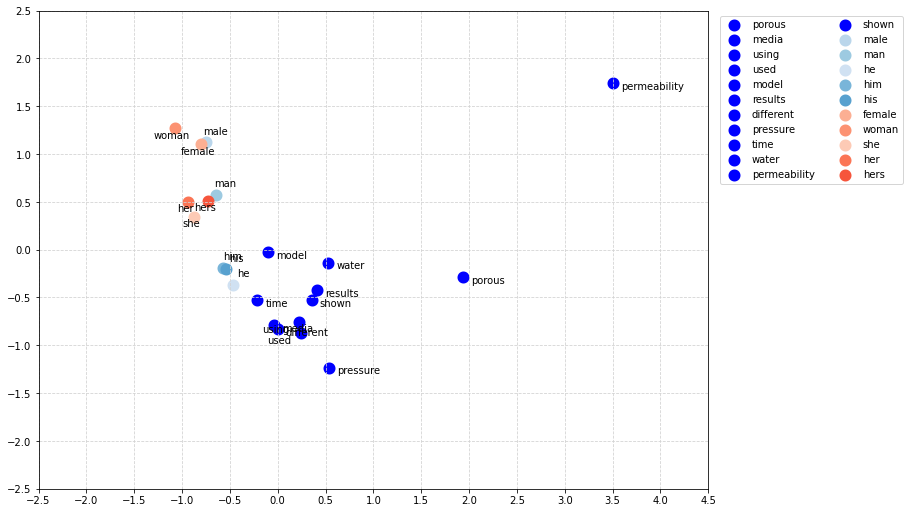

In [142]:
journal_name = 'Transport in Porous Media'

energy = pd.read_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/most_common_new.csv')

energy = [word for word in energy['Word'] if len(word) > 3]

energy = energy[:12]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = model[word]
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

new=pd.DataFrame(all_values)
new.index=valid_words

pca = PCA(n_components=2)
result = pca.fit_transform(new)

pronouns = list(word_colours.keys())

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in word_colours]

cosine_similarities = {}

for pronoun in pronouns:
    idx_pronoun = new.index.get_loc(pronoun)
    vec_pronoun = result[idx_pronoun]

    for idx_word in non_pronoun_indices:
        word = new.index[idx_word]
        vec_word = result[idx_word]

        similarity = cosine_similarity(vec_pronoun, vec_word)

        cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/cosine_similarities.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)
    
    target = ['using', 'used']

    if word not in word_colours and word not in target:
        offset = (8, -6)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in target:
        offset = (-10, -10)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='right', fontsize=10, color='black')
    if word in male_words:
        offset = (10, 8)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (-3, -10)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')

plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')
plt.xticks(np.arange(x_min-0.5, x_max + 0.6, 0.5))
plt.yticks(np.arange(y_min-0.5, y_max + 0.6, 0.5))
plt.xlim(x_min-0.5, x_max+0.5)
plt.ylim(y_min-0.5, y_max+0.5)
plt.savefig(f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal_name}/gender_dimensions/word2vec_pretrained_transport.png', bbox_inches='tight')
plt.show()